
Audits real NASA GSFC OMNI2, NMDB (Oulu & Moscow), NOAA PSL Niño 3.4, and ECMWF ERA5 records (1996–2024).

In [1]:
import sys; sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
from src.physics.force_field import kalman_rts_smooth_1d

df = pd.read_parquet('../data/processed/aligned_helio_atmos_daily.parquet')
print(f'Aligned Dataset Shape: {df.shape} | Date Range: {df.index.min().date()} to {df.index.max().date()}')
df[['sw_speed_kms', 'b_scalar_nt', 'nm_oulu_pct_anom', 'wpwp_olr_wm2', 'nino34_anom']].describe().round(2)

Aligned Dataset Shape: (10593, 29) | Date Range: 1996-01-01 to 2024-12-31


,sw_speed_kms,b_scalar_nt,nm_oulu_pct_anom,wpwp_olr_wm2,nino34_anom
count,10590.00,10592.00,10590.00,10593.00,10593.00
mean,425.70,5.77,-5.90,302.26,27.62
std,94.62,2.55,5.03,14.87,0.86
min,255.58,1.35,-30.99,259.56,25.49
25%,355.71,4.04,-9.54,294.71,26.99
50%,405.08,5.26,-5.02,307.41,27.68
75%,476.45,6.84,-1.65,313.54,28.23
max,1003.26,33.45,2.21,326.13,29.54


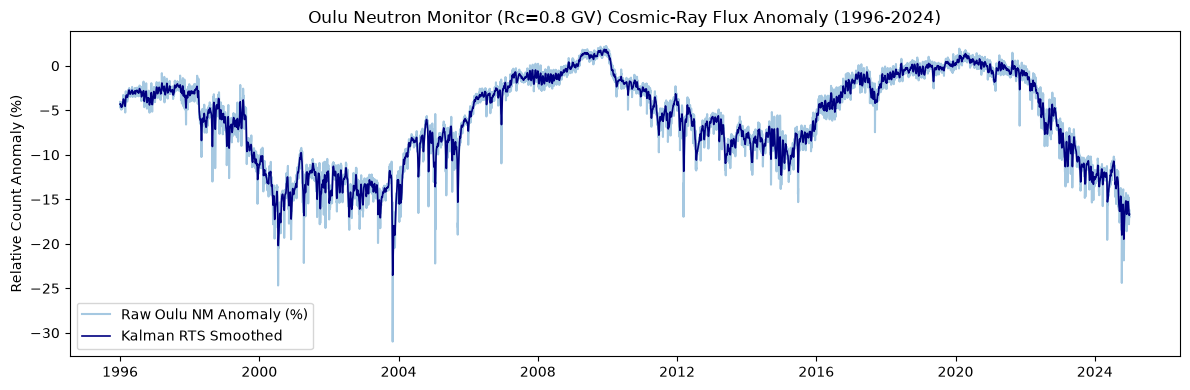

In [2]:
smoothed, std = kalman_rts_smooth_1d(df['nm_oulu_pct_anom'])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df['nm_oulu_pct_anom'], alpha=0.4, label='Raw Oulu NM Anomaly (%)')
ax.plot(smoothed.index, smoothed, color='navy', lw=1.2, label='Kalman RTS Smoothed')
ax.set_title('Oulu Neutron Monitor (Rc=0.8 GV) Cosmic-Ray Flux Anomaly (1996-2024)')
ax.set_ylabel('Relative Count Anomaly (%)')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/fig01_kalman_nmdb.png', dpi=180)
plt.show()